In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("/content/CAR DETAILS FROM CAR DEKHO (1).csv")

In [3]:
print("FIRST FIVE ROWS")
print(df.head())

print("\nDATASET SHAPE")
print(df.shape)

print("\nCOLUMN NAMES")
print(df.columns)

print("\nDATA TYPES")
print(df.dtypes)

FIRST FIVE ROWS
                       name  year  selling_price  km_driven    fuel  \
0             Maruti 800 AC  2007          60000      70000  Petrol   
1  Maruti Wagon R LXI Minor  2007         135000      50000  Petrol   
2      Hyundai Verna 1.6 SX  2012         600000     100000  Diesel   
3    Datsun RediGO T Option  2017         250000      46000  Petrol   
4     Honda Amaze VX i-DTEC  2014         450000     141000  Diesel   

  seller_type transmission         owner  
0  Individual       Manual   First Owner  
1  Individual       Manual   First Owner  
2  Individual       Manual   First Owner  
3  Individual       Manual   First Owner  
4  Individual       Manual  Second Owner  

DATASET SHAPE
(4340, 8)

COLUMN NAMES
Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner'],
      dtype='object')

DATA TYPES
name             object
year              int64
selling_price     int64
km_driven         int64
fuel             obje

In [4]:
# SECTION 3: CHECK DATA QUALITY

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nTOTAL MISSING VALUES")
print(df.isnull().sum().sum())

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nNUMERICAL COLUMNS")
print(df.select_dtypes(include="number").columns)

print("\nCATEGORICAL COLUMNS")
print(df.select_dtypes(include="object").columns)

# Store the number of rows before cleaning
before_cleaning = len(df)


MISSING VALUES
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

TOTAL MISSING VALUES
0

DUPLICATE ROWS
763

NUMERICAL COLUMNS
Index(['year', 'selling_price', 'km_driven'], dtype='object')

CATEGORICAL COLUMNS
Index(['name', 'fuel', 'seller_type', 'transmission', 'owner'], dtype='object')


In [8]:
#dataset cleaning
df = df.drop_duplicates()

df = df.dropna()

print("Rows after cleaning:", df.shape[0])

Rows after cleaning: 3577


In [6]:
after_cleaning = len(df)

print("\nROWS BEFORE CLEANING:", before_cleaning)
print("ROWS AFTER CLEANING:", after_cleaning)
print("ROWS REMOVED:", before_cleaning - after_cleaning)

print("\nMISSING VALUES AFTER CLEANING")
print(df.isnull().sum())

print("\nDUPLICATES AFTER CLEANING")
print(df.duplicated().sum())



ROWS BEFORE CLEANING: 4340
ROWS AFTER CLEANING: 3577
ROWS REMOVED: 763

MISSING VALUES AFTER CLEANING
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

DUPLICATES AFTER CLEANING
0


In [7]:
# SECTION 5: DESCRIPTIVE STATISTICS

print("\nNUMERICAL SUMMARY")
print(df.describe())

print("\nCATEGORICAL SUMMARY")
print(df.describe(include="object"))

print("\nCAR NAME COUNTS")
print(df["name"].value_counts().head(10))

print("\nFUEL TYPE COUNTS")
print(df["fuel"].value_counts())

print("\nSELLER TYPE COUNTS")
print(df["seller_type"].value_counts())

print("\nTRANSMISSION COUNTS")
print(df["transmission"].value_counts())

print("\nOWNER COUNTS")
print(df["owner"].value_counts())


NUMERICAL SUMMARY
              year  selling_price      km_driven
count  3577.000000   3.577000e+03    3577.000000
mean   2012.962538   4.739125e+05   69250.545709
std       4.251759   5.093018e+05   47579.940016
min    1992.000000   2.000000e+04       1.000000
25%    2010.000000   2.000000e+05   36000.000000
50%    2013.000000   3.500000e+05   60000.000000
75%    2016.000000   6.000000e+05   90000.000000
max    2020.000000   8.900000e+06  806599.000000

CATEGORICAL SUMMARY
                          name    fuel seller_type transmission        owner
count                     3577    3577        3577         3577         3577
unique                    1491       5           3            2            5
top     Maruti Swift Dzire VDI  Diesel  Individual       Manual  First Owner
freq                        54    1800        2832         3265         2218

CAR NAME COUNTS
name
Maruti Swift Dzire VDI      54
Maruti Alto 800 LXI         48
Maruti Alto LXi             42
Maruti Alto LX     

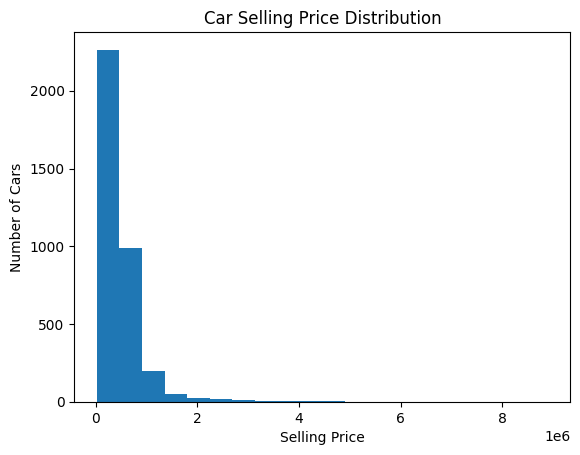

Observation: This chart shows the distribution of car prices.


In [11]:
# SECTION 6: UNIVARIATE ANALYSIS
# CHART 1: HISTOGRAM OF SELLING PRICE
plt.hist(df["selling_price"], bins=20)
plt.title("Car Selling Price Distribution")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.show()
print("Observation: This chart shows the distribution of car prices.")


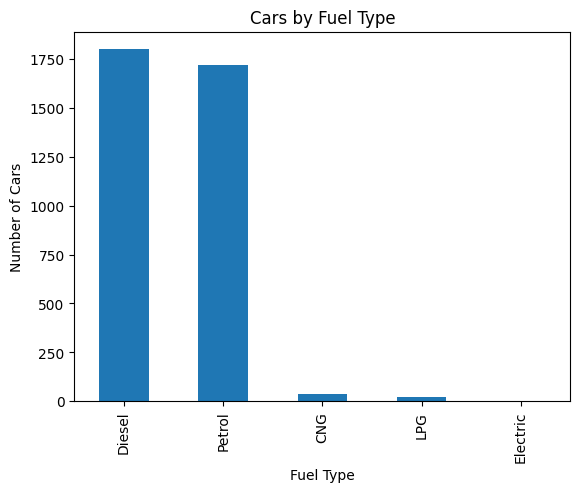

In [12]:
#  CHART 2: Bar chart - Fuel type

df["fuel"].value_counts().plot(kind="bar")
plt.title("Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")
plt.show()


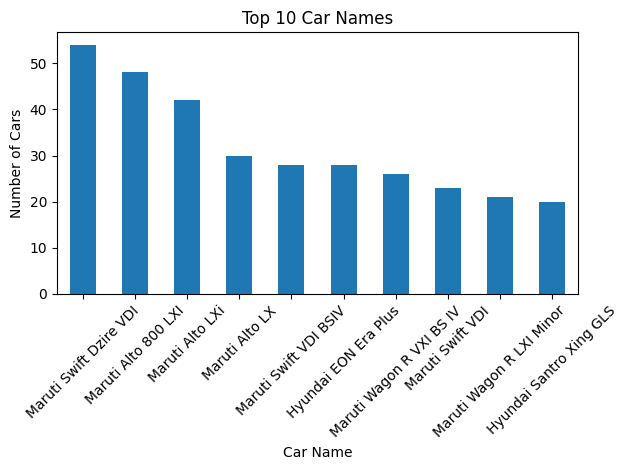

In [13]:
# Chart 3: Bar chart - Top 10 car names

df["name"].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 Car Names")
plt.xlabel("Car Name")
plt.ylabel("Number of Cars")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

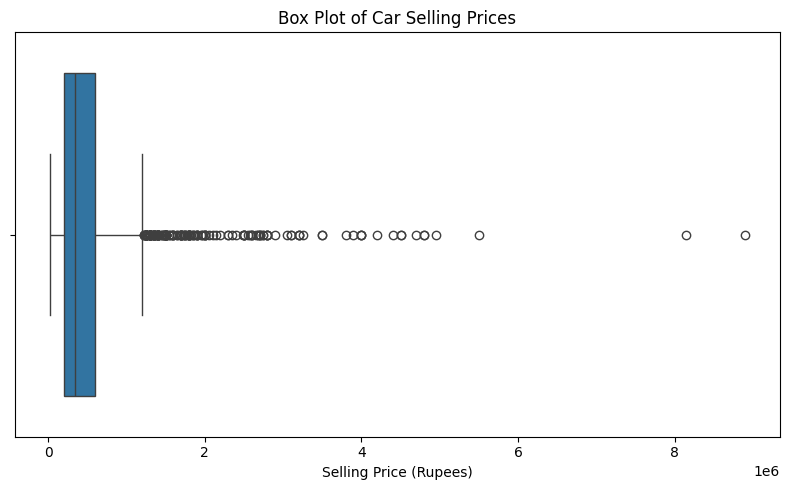


LOWER OUTLIER LIMIT: -400000.0
UPPER OUTLIER LIMIT: 1200000.0
NUMBER OF POTENTIAL PRICE OUTLIERS: 170
Observation: Some cars may have unusually high or low prices.


In [31]:
# SECTION 7: OUTLIER ANALYSIS
# CHART 4: BOX PLOT OF SELLING PRICE

plt.figure(figsize=(8, 5))

sns.boxplot(x=df["selling_price"])

plt.title("Box Plot of Car Selling Prices")
plt.xlabel("Selling Price (Rupees)")

plt.tight_layout()
plt.show()

# Calculate the IQR to identify potential outliers
Q1 = df["selling_price"].quantile(0.25)
Q3 = df["selling_price"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["selling_price"] < lower_limit) |
    (df["selling_price"] > upper_limit)
]

print("\nLOWER OUTLIER LIMIT:", lower_limit)
print("UPPER OUTLIER LIMIT:", upper_limit)
print("NUMBER OF POTENTIAL PRICE OUTLIERS:", len(outliers))

# We identify outliers but do not automatically delete them
print("Observation: Some cars may have unusually high or low prices.")


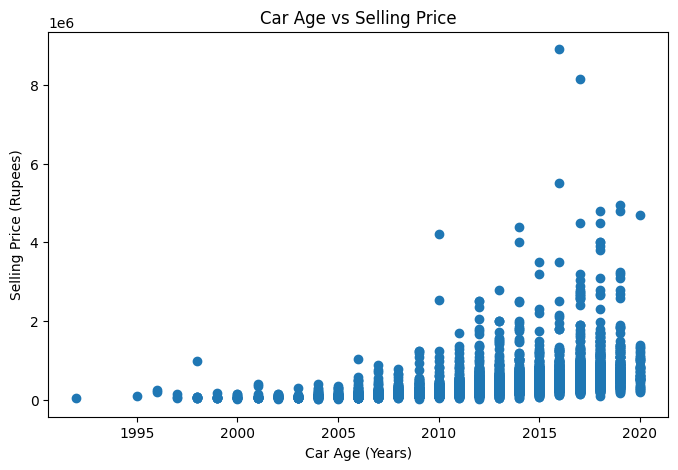

Observation: This chart shows the relationship between car age and price.


In [21]:
# SECTION 8: BIVARIATE ANALYSIS
# CHART 5: CAR AGE VS SELLING PRICE

plt.figure(figsize=(8, 5))

plt.scatter(df["year"], df["selling_price"])

plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price (Rupees)")

plt.show()

print("Observation: This chart shows the relationship between car age and price.")

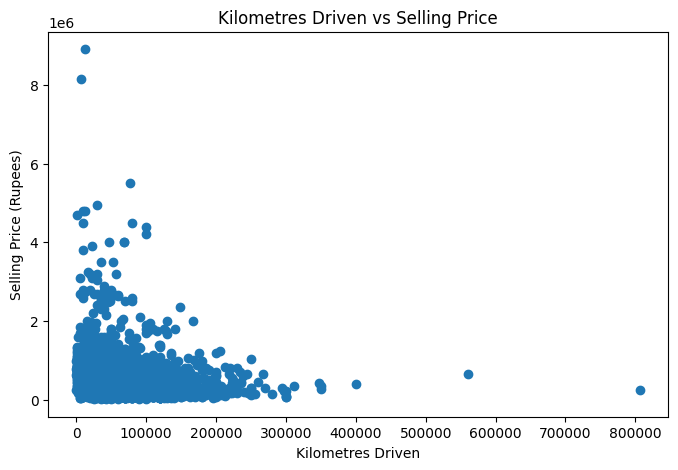

Observation: This chart shows the relationship between distance driven and price.


In [22]:
# CHART 6: KILOMETRES DRIVEN VS SELLING PRICE

plt.figure(figsize=(8, 5))

plt.scatter(df["km_driven"], df["selling_price"])

plt.title("Kilometres Driven vs Selling Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price (Rupees)")
plt.show()

print("Observation: This chart shows the relationship between distance driven and price.")

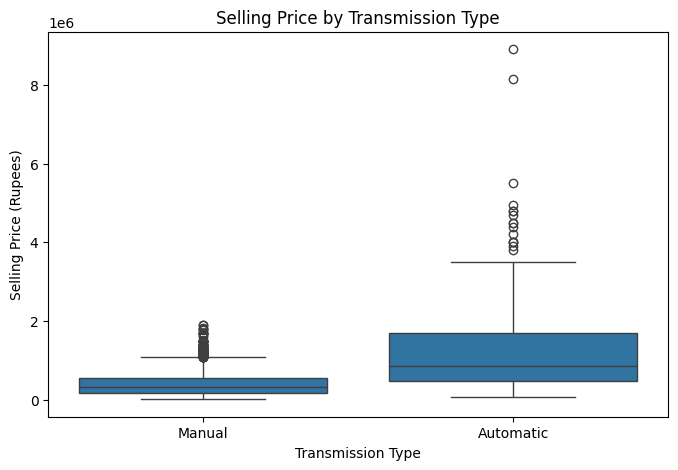

Observation: This chart compares prices of manual and automatic cars.


In [23]:
# CHART 7: TRANSMISSION VS SELLING PRICE

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="transmission", y="selling_price")

plt.title("Selling Price by Transmission Type")
plt.xlabel("Transmission Type")
plt.ylabel("Selling Price (Rupees)")
plt.show()

print("Observation: This chart compares prices of manual and automatic cars.")

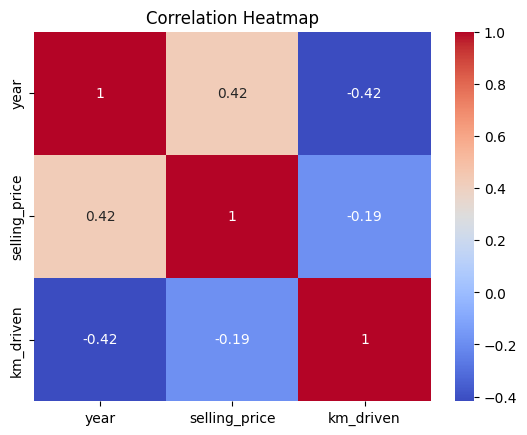

Observation: The heatmap shows relationships between numerical features.


In [25]:
# SECTION 9: MULTIVARIATE ANALYSIS
# CHART 8: CORRELATION HEATMAP
sns.heatmap(
    df[["year", "selling_price", "km_driven"]].corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Correlation Heatmap")
plt.show()
print("Observation: The heatmap shows relationships between numerical features.")

In [27]:
# SECTION 10: GROUP ANALYSIS

print("\nAVERAGE PRICE BY FUEL TYPE")

print(
    df.groupby("fuel")["selling_price"]
    .mean()
    .sort_values(ascending=False)
)

print("\nAVERAGE PRICE BY TRANSMISSION")

print(
    df.groupby("transmission")["selling_price"]
    .mean()
)

print("\nAVERAGE PRICE BY SELLER TYPE")

print(
    df.groupby("seller_type")["selling_price"]
    .mean()
    .sort_values(ascending=False)
)


AVERAGE PRICE BY FUEL TYPE
fuel
Diesel      614001.075000
Petrol      335344.340128
Electric    310000.000000
CNG         273162.081081
LPG         171818.136364
Name: selling_price, dtype: float64

AVERAGE PRICE BY TRANSMISSION
transmission
Automatic    1.274955e+06
Manual       3.973657e+05
Name: selling_price, dtype: float64

AVERAGE PRICE BY SELLER TYPE
seller_type
Trustmark Dealer    822272.727273
Dealer              652699.390449
Individual          424904.024364
Name: selling_price, dtype: float64


In [30]:

# SECTION 11: Five data-based findings

print("\nKEY FINDINGS")

print("1. Most common car name:")
print(df["name"].value_counts().idxmax())

print("\n2. Most common fuel type:")
print(df["fuel"].value_counts().idxmax())

print("\n3. Average selling price:")
print(df["selling_price"].mean())

print("\n4. Average kilometres driven:")
print(df["km_driven"].mean())

print("\n5. Correlation between car age and selling price:")
print(df["year"].corr(df["selling_price"]))



KEY FINDINGS
1. Most common car name:
Maruti Swift Dzire VDI

2. Most common fuel type:
Diesel

3. Average selling price:
473912.54207436397

4. Average kilometres driven:
69250.54570869444

5. Correlation between car age and selling price:
0.424260081542695
